# Week 3: Sketch to image

To start, save a copy to your Drive (File → Save a copy in Drive), then run the cells in order. The images are made on Replicate, so it runs on Colab's free CPU runtime. You will need the course Replicate token, which the instructor shares in the first studio. Add it in Colab's Secrets panel (the key icon on the left) with the name REPLICATE_API_TOKEN. The outputs below are from the chair sketch in the week 3 slides.

## 1. Setup

This reads your Replicate token from Colab's Secrets. If it is not there, it will ask you to paste it. If Replicate does not accept the token, the cell stops and says so.

In [1]:
import base64, io, os, sys, time
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install pillow-heif
import requests
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
try:
    from pillow_heif import register_heif_opener
    register_heif_opener()  # so that iPhone .heic photos open like any other image
except ImportError:
    pass

token = os.environ.get("REPLICATE_API_TOKEN")
if IN_COLAB and not token:
    try:
        from google.colab import userdata
        token = userdata.get("REPLICATE_API_TOKEN")
    except Exception:
        token = None
if not token:
    import getpass
    token = getpass.getpass("Replicate token: ")
HEADERS = {"Authorization": f"Bearer {token}", "Content-Type": "application/json"}
if requests.get("https://api.replicate.com/v1/account", headers=HEADERS, timeout=60).status_code != 200:
    raise ValueError("Replicate did not accept this token. Check REPLICATE_API_TOKEN in Colab's Secrets panel.")
EXAMPLE = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/chair-sketch/"
print("ready")

ready


## 2. Your sketch

With USE_EXAMPLE = True, it downloads the chair sketch from the slides. To use your own, set it to False and run the cell again. It will ask for a photo of your sketch (a photo from an iPhone in .heic works too). It then turns the photo into dark lines on white and shows the two side by side. If parts of your lines go missing, raise THRESHOLD and run the cell again. If a shadow turns into a black patch, lower it.

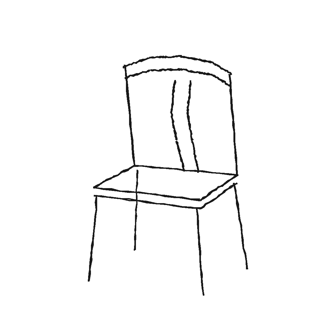

In [2]:
USE_EXAMPLE = True  # True: the chair sketch from the week 3 slides. False: upload a photo of your own sketch.
THRESHOLD = 140     # for a photo of a sketch: pixels darker than this (0 to 255) become lines. Raise it if lines go missing, lower it if shadows turn black.

def clean_sketch(im):
    """Turn a photo of a pencil or pen sketch into dark lines on white, on a square canvas."""
    g = ImageOps.autocontrast(ImageOps.grayscale(im), cutoff=2)
    g = g.point(lambda v: 0 if v < THRESHOLD else 255)
    side = max(g.size)
    canvas = Image.new("L", (side, side), 255)
    canvas.paste(g, ((side - g.width) // 2, (side - g.height) // 2))
    return canvas.resize((1024, 1024)).convert("RGB")

def get_sketch(example_name):
    """The example sketch as it is, or your photo next to the cleaned sketch made from it."""
    if USE_EXAMPLE:
        if not os.path.exists(example_name):
            open(example_name, "wb").write(requests.get(EXAMPLE + example_name, timeout=60).content)
        sk = Image.open(example_name).convert("RGB")
        display(sk.resize((320, 320)))
        return sk
    from google.colab import files
    print("Pick a photo of your sketch:")
    data = next(iter(files.upload().values()))
    photo = ImageOps.exif_transpose(Image.open(io.BytesIO(data))).convert("RGB")
    photo.thumbnail((2048, 2048))
    sk = clean_sketch(photo)
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.4))
    for ax, im, title in zip(axes, [photo, sk], ["your photo", f"cleaned, THRESHOLD = {THRESHOLD}"]):
        ax.imshow(im)
        ax.set_title(title, loc="left", fontsize=11)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return sk

sketch = get_sketch("sketch.png")
sketch.save("my-sketch.png")

## 3. Your prompt

Write what the design is and what it is made of, for example "a side chair for a museum cafe, oak". The sketch sets the shape, so the words mostly change the material and color.

In [3]:
PROMPT = "a side chair for a museum cafe, oak, product photo on a plain grey backdrop"
SEEDS = [1, 2, 3, 4]

## 4. Make the images

It makes one image for each of the four seeds in SEEDS with FLUX.1 Canny [dev], a model that follows the edges in your sketch. Each image takes about 15 seconds and costs about 2.5 US cents.

seed 1 done


seed 2 done


seed 3 done


seed 4 done


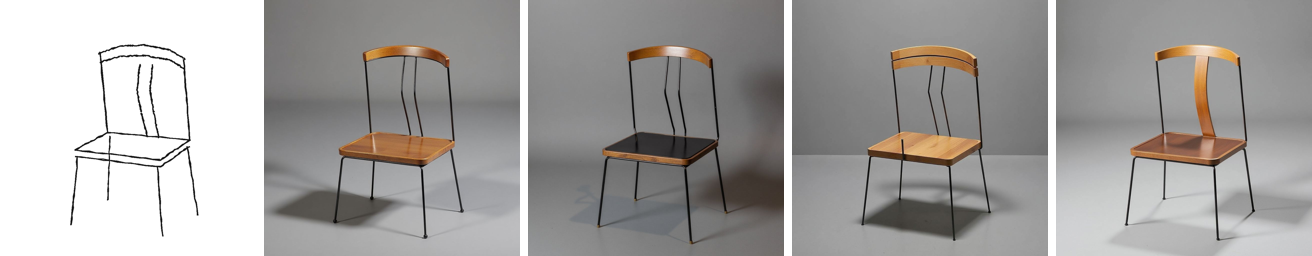

In [4]:
def run(model, inp):
    """Run one model on Replicate, wait for it, and return the image it made."""
    r = requests.post(f"https://api.replicate.com/v1/models/{model}/predictions",
                      headers=HEADERS, json={"input": inp}, timeout=300)
    if r.status_code >= 400:
        raise RuntimeError(f"Replicate did not start {model}: {r.json().get('detail', r.text)}")
    r = r.json()
    while r.get("status") not in ("succeeded", "failed", "canceled"):
        time.sleep(2)
        r = requests.get(r["urls"]["get"], headers=HEADERS, timeout=60).json()
    if r["status"] != "succeeded":
        raise RuntimeError(f"{model} failed: {r.get('error')}")
    url = r["output"][0] if isinstance(r["output"], list) else r["output"]
    return Image.open(io.BytesIO(requests.get(url, timeout=120).content)).convert("RGB")

def data_url(im, fmt):
    buf = io.BytesIO()
    im.save(buf, format=fmt, quality=95)
    return f"data:image/{fmt.lower()};base64," + base64.b64encode(buf.getvalue()).decode()

def sketch_to_image(sk, prompt, seed):
    """One image from FLUX.1 Canny [dev], which follows the edges of the sketch."""
    return run("black-forest-labs/flux-canny-dev",
               {"prompt": prompt, "seed": seed, "output_format": "jpg", "control_image": data_url(sk, "PNG")})

def row(images, size=256):
    out = Image.new("RGB", (len(images) * (size + 8) - 8, size), "white")
    for i, im in enumerate(images):
        out.paste(im.resize((size, size)), (i * (size + 8), 0))
    return out

results = []
for s in SEEDS:
    im = sketch_to_image(sketch, PROMPT, s)
    im.save(f"image-seed-{s}.jpg")
    results.append(im)
    print(f"seed {s} done")
row([sketch] + results)

## 5. Change one thing and run again

With USE_EXAMPLE = True, it uses the same chair, with the legs and back posts redrawn as outlines instead of solid lines. With your own sketch, it will ask for a photo of the changed sketch. It runs the first seed again so you can compare the two.

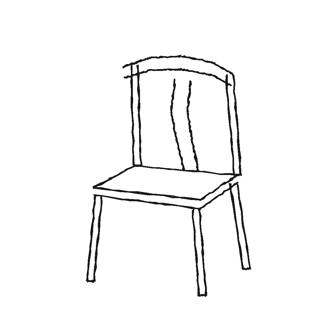

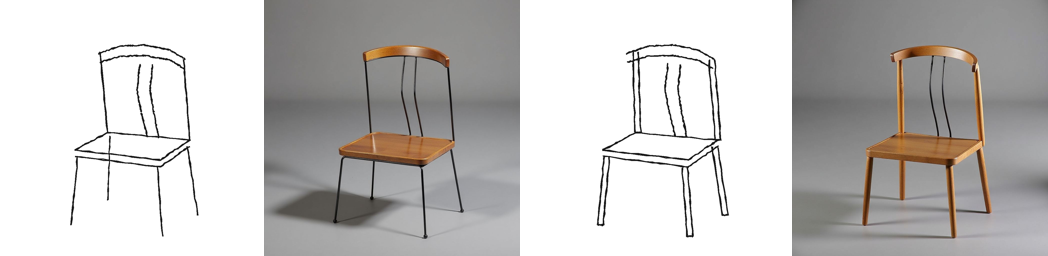

In [5]:
sketch2 = get_sketch("sketch2.png")
sketch2.save("my-sketch-2.png")
again = sketch_to_image(sketch2, PROMPT, SEEDS[0])
again.save(f"image-2-seed-{SEEDS[0]}.jpg")
row([sketch, results[0], sketch2, again])

## 6. The same change in words

Write the change you made to your sketch as an instruction in EDIT, for example "make the legs and back posts solid oak instead of black metal". It gives your first image and the instruction to FLUX.1 Kontext [pro], a model that edits an image from words. It uses the same seed as your first image. The edit takes about 10 seconds and costs about 4 US cents. Then it puts your two sketches and the three images side by side, and saves them as comparison.jpg. For the hand-in, download comparison.jpg from the Files panel on the left, and write a few sentences on whether your redrawn sketch or the change in words got closer to what you wanted, and why.

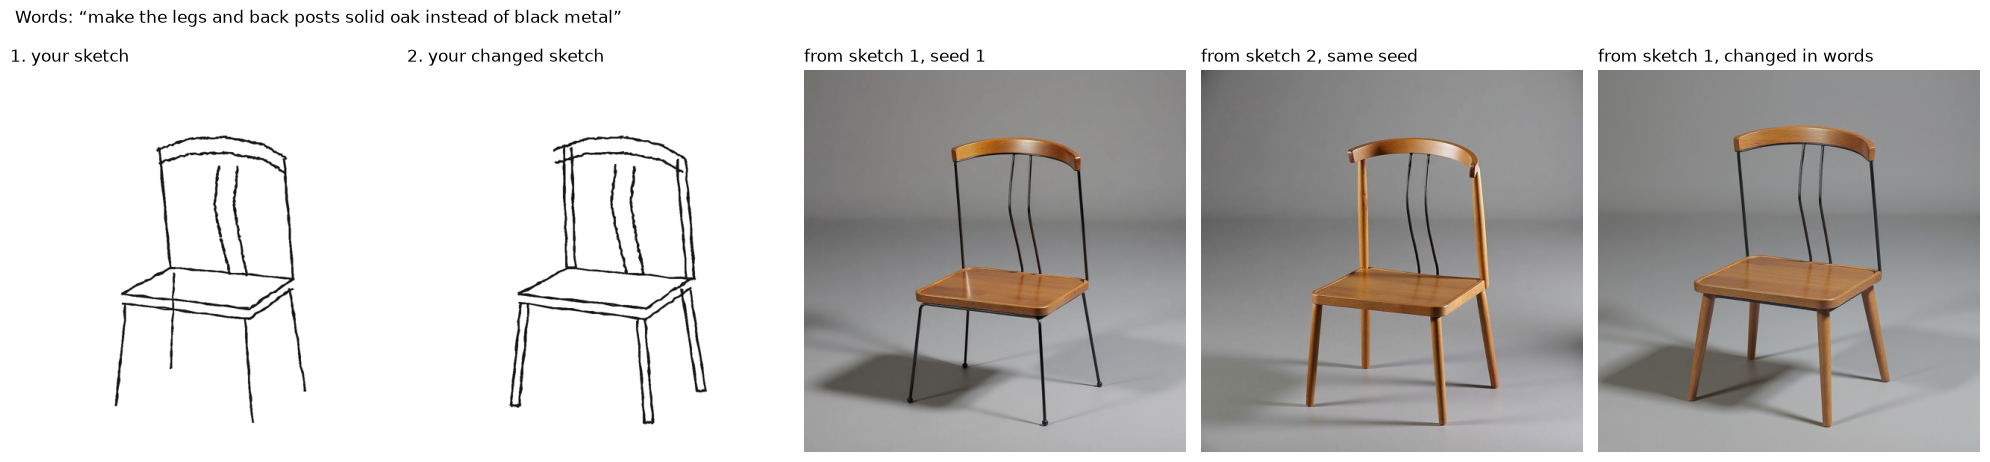

Saved comparison.jpg


In [6]:
# Describe the change you made to the sketch, as an instruction to an editing model.
EDIT = "make the legs and back posts solid oak instead of black metal"

def edit_image(im, instruction, seed):
    """One edit from FLUX.1 Kontext [pro], which changes an image from an instruction in words."""
    return run("black-forest-labs/flux-kontext-pro",
               {"prompt": instruction, "seed": seed, "output_format": "jpg", "input_image": data_url(im, "JPEG")})

in_words = edit_image(results[0], EDIT, SEEDS[0])
in_words.save(f"image-words-seed-{SEEDS[0]}.jpg")
panels = [(sketch, "1. your sketch"), (sketch2, "2. your changed sketch"), (results[0], f"from sketch 1, seed {SEEDS[0]}"),
          (again, "from sketch 2, same seed"), (in_words, "from sketch 1, changed in words")]
fig, axes = plt.subplots(1, 5, figsize=(20, 4.9))
for ax, (im, title) in zip(axes, panels):
    ax.imshow(im.resize((512, 512)))
    ax.set_title(title, loc="left", fontsize=12)
    ax.axis("off")
fig.suptitle(f"Words: “{EDIT}”", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.savefig("comparison.jpg", dpi=100)
plt.show()
print("Saved comparison.jpg")